theta = 20.5
SRS bias = -0.04422000000000281 SE = 4.944029220594617 P(first in sample) = 0.1253
With replacement bias = 0.012019999999999698 SE = 5.12408051651357 P(first in sample) = 0.1167
Theory SRS: SE = 4.890466917040404 P = 0.125
Theory WR:  SE = 5.162363799656123 P = 0.11890430664062512


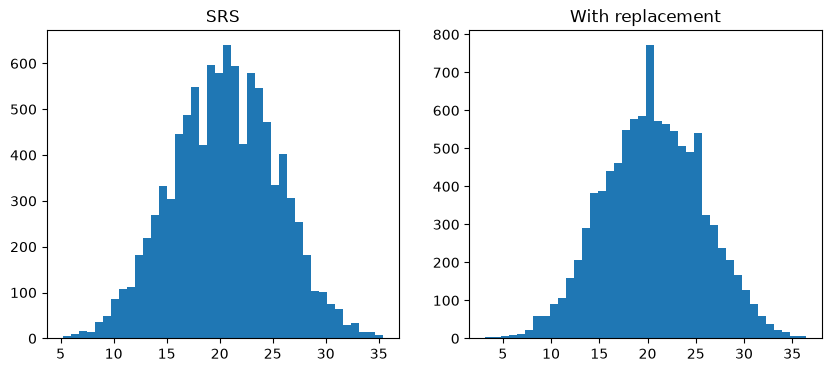

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
N, n, R = 40, 5, 10000
S = np.arange(1, N + 1)

theta = S.mean()
print("theta =", theta)

srs = np.array([rng.choice(S, n, replace=False) for _ in range(R)])
wr = rng.choice(S, (R, n), replace=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for a, (name, X) in zip(ax, [("SRS", srs), ("With replacement", wr)]):
    means = X.mean(axis=1)
    a.hist(means, bins=40)
    a.set_title(name)

    bias = means.mean() - theta
    se = means.std(ddof=1)
    p_first = (X == 1).any(axis=1).mean()
    print(name, "bias =", bias, "SE =", se, "P(first in sample) =", p_first)

sigma2 = S.var()
print("Theory SRS: SE =", np.sqrt(sigma2 / n * (N - n) / (N - 1)), "P =", n / N)
print("Theory WR:  SE =", np.sqrt(sigma2 / n), "P =", 1 - (1 - 1 / N) ** n)

plt.show()